# 01 — Exploración de Fruit Quality Classification

En este cuaderno revisamos la fuente pública antes de preparar los modelos. Contamos imágenes por calidad y fruta, comprobamos dimensiones y decodificación, buscamos duplicados exactos y observamos ejemplos. Conservamos Mixed como material pendiente de revisión porque un archivo puede contener varios productos y calidades. La colección propia y el acuerdo de etiquetas quedan para el siguiente trabajo del equipo.

Fuente: [Fruit Quality Classification en Kaggle](https://www.kaggle.com/datasets/ryandpark/fruit-quality-classification). Los originales se leen desde data/raw/kaggle y no se guardan en Git.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Abra el cuaderno desde la raíz del repositorio.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
RAW_KAGGLE = ROOT / "data" / "raw" / "kaggle"
assert RAW_KAGGLE.is_dir(), f"No existe el conjunto descargado: {RAW_KAGGLE}"
print(f"Repositorio: {ROOT}")
print(f"Fuente pública: {RAW_KAGGLE}")

Repositorio: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton
Fuente pública: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton\data\raw\kaggle


In [2]:
from concurrent.futures import ThreadPoolExecutor
import hashlib
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from tqdm import tqdm

from src.data.dataset import scan_labeled_dataset

labeled_df, mixed_df = scan_labeled_dataset(RAW_KAGGLE, "kaggle")
mixed_display = mixed_df.copy()
mixed_display["quality"] = "MixedPending"
records = pd.concat([labeled_df, mixed_display], ignore_index=True)
records["quality"] = records["quality"].replace({"": "MixedPending"})

class_counts = records["quality"].value_counts().reindex(
    ["Good", "Regular", "Bad", "MixedPending"], fill_value=0
)
print(f"Imágenes detectadas: {len(records):,}")
print(f"Supervisadas: {len(labeled_df):,}; escenas Mixed pendientes: {len(mixed_df):,}")
display(class_counts.rename("images").to_frame())
display(pd.crosstab(records["fruit"], records["quality"]))

audit_reference = {"Good": 11_664, "Bad": 6_788, "MixedPending": 1_074}
brief_bad_count = 6_778
observed = class_counts[class_counts > 0].to_dict()
print("Conteos observados:", observed)
print("Referencia de auditoría previa:", audit_reference)
if observed.get("Bad") == audit_reference["Bad"] and observed["Bad"] != brief_bad_count:
    print(f"Diferencia pendiente: auditoría={observed['Bad']:,}, enunciado={brief_bad_count:,}; explicar versión/conteo de archivos en el informe.")
else:
    print("Compare el conteo Bad observado con la cifra del enunciado antes de cerrar el informe.")

Imágenes detectadas: 19,526
Supervisadas: 18,452; escenas Mixed pendientes: 1,074


,images
quality,
Good,11664
Regular,0
Bad,6788
MixedPending,1074


quality,Bad,Good,MixedPending
fruit,,,
Apple,1141,1149,113
Banana,1087,1113,285
Guava,1129,1152,148
Lemon,0,0,278
Lime,1085,1094,0
Orange,1159,1216,125
Pomegranate,1187,5940,125


## Integridad, resolución y duplicados exactos

Decodificamos cada archivo para comprobar que se puede abrir. En la misma lectura calculamos SHA-256 para identificar copias binarias repetidas.

In [3]:
def inspect_image(path):
    path = Path(path)
    payload = path.read_bytes()
    image = cv2.imdecode(np.frombuffer(payload, dtype=np.uint8), cv2.IMREAD_UNCHANGED)
    digest = hashlib.sha256(payload).hexdigest()
    if image is None or image.size == 0:
        return {"path": str(path), "readable": False, "width": None, "height": None, "sha256": digest}
    height, width = image.shape[:2]
    return {"path": str(path), "readable": True, "width": width, "height": height, "sha256": digest}

paths = records["path"].astype(str).tolist()
workers = min(8, os.cpu_count() or 1)
with ThreadPoolExecutor(max_workers=workers) as pool:
    audit_rows = list(tqdm(pool.map(inspect_image, paths), total=len(paths), desc="Auditoría de imágenes", mininterval=5, miniters=1_000, ascii=True))
audit_df = pd.DataFrame(audit_rows)
unreadable = audit_df.loc[~audit_df["readable"]]
dimensions = audit_df.groupby(["width", "height"], dropna=False).size().sort_values(ascending=False)
hash_counts = audit_df["sha256"].value_counts()
duplicate_hashes = hash_counts[hash_counts > 1]
duplicate_files = int((duplicate_hashes - 1).sum())

print(f"Legibles: {int(audit_df['readable'].sum()):,}/{len(audit_df):,}")
print(f"Ilegibles: {len(unreadable):,}")
print(f"Grupos de duplicados binarios: {len(duplicate_hashes):,}; copias adicionales: {duplicate_files:,}")
display(dimensions.head(10).rename("images").to_frame())
if not unreadable.empty:
    display(unreadable.head(20))
if len(duplicate_hashes):
    display(audit_df[audit_df["sha256"].isin(duplicate_hashes.index)].sort_values("sha256").head(20))
assert len(unreadable) == 0, "Hay imágenes ilegibles; revise la tabla anterior."

Auditoría de imágenes:   0%|          | 0/19526 [00:00<?, ?it/s]

Auditoría de imágenes:  24%|##3       | 4667/19526 [00:05<00:15, 928.76it/s]

Auditoría de imágenes:  49%|####8     | 9552/19526 [00:10<00:10, 956.17it/s]

Auditoría de imágenes:  74%|#######3  | 14366/19526 [00:15<00:05, 958.86it/s]

Auditoría de imágenes:  90%|########9 | 17515/19526 [00:21<00:02, 732.69it/s]

Auditoría de imágenes:  90%|########9 | 17515/19526 [00:40<00:02, 732.69it/s]

... (14 outputs left out)

Auditoría de imágenes: 100%|#########9| 19489/19526 [01:54<00:00, 77.33it/s]

Auditoría de imágenes: 100%|##########| 19526/19526 [01:55<00:00, 169.71it/s]

Legibles: 19,526/19,526
Ilegibles: 0
Grupos de duplicados binarios: 0; copias adicionales: 0


,,images
width,height,
256,256,12508
192,256,4536
256,192,1897
3000,4000,381
8000,6000,183
144,256,12
256,144,9


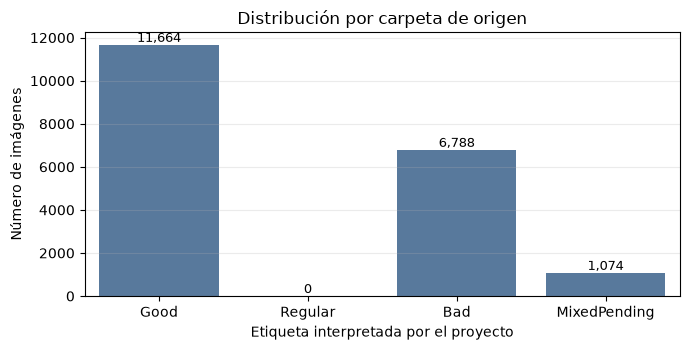

Figura guardada en: C:\Users\Home\Downloads\uni\apo3\proyecto final\apo3-mangoMelocoton\docs\figures\kaggle_quality_distribution.png


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
plot_data = class_counts.reindex(["Good", "Regular", "Bad", "MixedPending"])
sns.barplot(x=plot_data.index, y=plot_data.values, color="#4C78A8", ax=ax)
ax.set_title("Distribución por carpeta de origen")
ax.set_xlabel("Etiqueta interpretada por el proyecto")
ax.set_ylabel("Número de imágenes")
ax.grid(axis="y", alpha=0.25)
for i, value in enumerate(plot_data.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom", fontsize=9)
fig.tight_layout()
figure_path = ROOT / "docs" / "figures" / "kaggle_quality_distribution.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figura guardada en: {figure_path}")

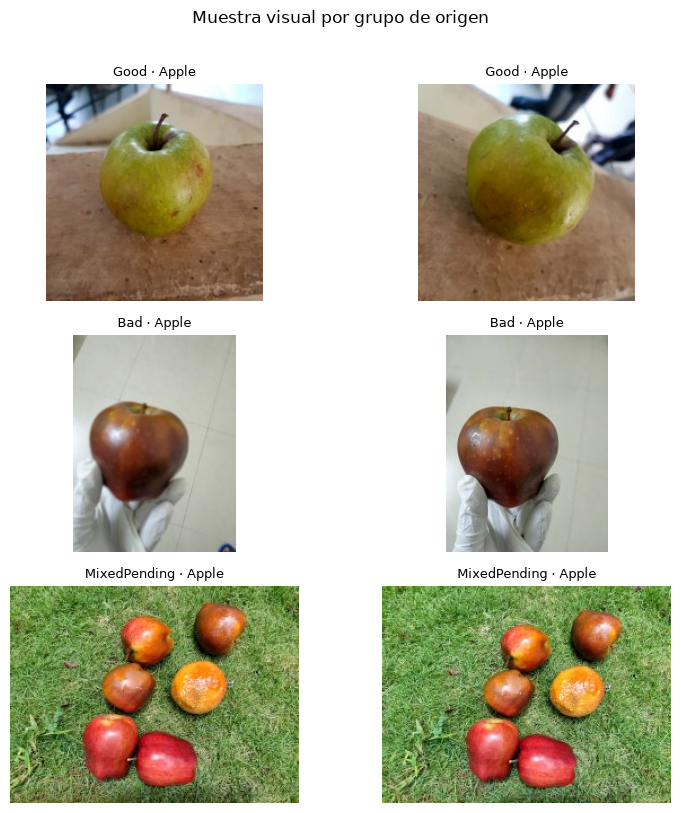

In [5]:
quality_order = ["Good", "Bad", "MixedPending"]
fig, axes = plt.subplots(len(quality_order), 2, figsize=(8, 8))
for row, quality in enumerate(quality_order):
    samples = records.loc[records["quality"] == quality].head(2)
    for col in range(2):
        ax = axes[row, col]
        ax.axis("off")
        if col >= len(samples):
            continue
        record = samples.iloc[col]
        image = cv2.imread(record["path"])
        if image is not None:
            h, w = image.shape[:2]
            scale = min(1.0, 640 / max(h, w))
            if scale < 1.0:
                image = cv2.resize(image, (round(w * scale), round(h * scale)))
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
            ax.set_title(f"{quality} · {record['fruit']}", fontsize=9)
fig.suptitle("Muestra visual por grupo de origen", y=1.01)
fig.tight_layout()
plt.show()

## Hallazgos de la exploración

La descarga contiene dos clases supervisadas, Good y Bad, y 1.074 escenas Mixed sin etiquetas individuales. El mapa del código también reserva Regular, pero la fuente pública no aporta esa clase. Confirmamos la legibilidad completa y revisamos duplicados exactos y resoluciones en las tablas anteriores. En la preparación usamos Good y Bad, y mantenemos los recortes Mixed sin etiqueta hasta su revisión.